# BTTS Model Training Notebook

This notebook trains the first practical BTTS model for the betPawa virtual English League data you are collecting.

Core rule used here:

```text
If MD 23 is live and we are predicting MD 24:
features must use results only up to MD 22 + MD 24 odds.
```

So during training we create every historical row the same way: `feature_cutoff_matchday = target_matchday - 2`.

## 1. Setup

Run this notebook from the project root, or from the `notebooks` folder. It expects your current files:

- `data/match_day_results/match_results_master.csv`
- `data/odds/final_odds/final_odds_master.csv`

Run the dependency setup cell once if the notebook kernel says a package like `numpy` is missing.


In [4]:
# Run this cell once if imports fail in this notebook kernel.
import importlib.util
import subprocess
import sys

required_packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "joblib": "joblib",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
}
missing = [package for module, package in required_packages.items() if importlib.util.find_spec(module) is None]

if missing:
    print("Installing missing packages into this notebook kernel:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("Notebook dependencies are already installed.")


Notebook dependencies are already installed.


In [5]:
from pathlib import Path
import json
import os
import warnings

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import dump, load
from sklearn.ensemble import ExtraTreesClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, brier_score_loss, classification_report, confusion_matrix, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RESULTS_PATH = PROJECT_ROOT / "data" / "match_day_results" / "match_results_master.csv"
ODDS_PATH = PROJECT_ROOT / "data" / "odds" / "final_odds" / "final_odds_master.csv"
RAW_ODDS_DIR = PROJECT_ROOT / "data" / "odds" / "all_odds_files"
MODEL_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROJECT_ROOT / "data" / "outputs"

MODEL_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

LIVE_GAP_MATCHDAYS = 2
PICK_THRESHOLD = 0.65
RANDOM_STATE = 42

print("Project root:", PROJECT_ROOT)
print("Results file:", RESULTS_PATH)
print("Odds file:", ODDS_PATH)
print("Raw odds archive:", RAW_ODDS_DIR)

Project root: D:\Codex things\BP
Results file: D:\Codex things\BP\data\match_day_results\match_results_master.csv
Odds file: D:\Codex things\BP\data\odds\final_odds\final_odds_master.csv
Raw odds archive: D:\Codex things\BP\data\odds\all_odds_files


## 2. Load Results And Create Target

`target_btts` is the answer during training:

```text
1 = both teams scored
0 = one or both teams failed to score
```

In [6]:
def load_results(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    df["season_id"] = df["season_id"].astype(str)
    df["home_team"] = df["home_team"].astype(str).str.upper().str.strip()
    df["away_team"] = df["away_team"].astype(str).str.upper().str.strip()
    numeric_cols = [
        "matchday",
        "halftime_home_goals",
        "halftime_away_goals",
        "fulltime_home_goals",
        "fulltime_away_goals",
    ]
    for col in numeric_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    df = df.dropna(subset=["matchday", "fulltime_home_goals", "fulltime_away_goals"])
    df["matchday"] = df["matchday"].astype(int)
    df["fulltime_home_goals"] = df["fulltime_home_goals"].astype(int)
    df["fulltime_away_goals"] = df["fulltime_away_goals"].astype(int)
    df = df.drop_duplicates(["season_id", "matchday", "home_team", "away_team"])
    df = df.sort_values(["season_id", "matchday", "home_team", "away_team"]).reset_index(drop=True)
    df["target_btts"] = ((df["fulltime_home_goals"] > 0) & (df["fulltime_away_goals"] > 0)).astype(int)
    return df


results = load_results(RESULTS_PATH)
display(results.head())
print("Rows:", len(results))
print("Seasons:", results["season_id"].nunique())
print("BTTS rate:", round(results["target_btts"].mean(), 3))

,season_id,matchday,home_team,away_team,halftime_home_goals,halftime_away_goals,fulltime_home_goals,fulltime_away_goals,captured_at,target_btts
0,138470,1,AST,ARS,0,1,1,1,2026-07-22T17:08:20+00:00,1
1,138470,1,BHA,CRY,2,1,3,2,2026-07-22T17:08:20+00:00,1
2,138470,1,BOU,FUL,0,2,0,4,2026-07-22T17:08:20+00:00,0
3,138470,1,BRE,WOL,1,0,1,2,2026-07-22T17:08:20+00:00,1
4,138470,1,LEE,EVE,1,0,2,1,2026-07-22T17:08:20+00:00,1


Rows: 64142
Seasons: 281
BTTS rate: 0.583


## 3. Load Odds

The notebook uses the source-of-truth final odds file:

```text
data/odds/final_odds/final_odds_master.csv
```

That file is already wide, with one row per unique fixture based on `home_team + away_team`.

Main odds columns used:

```text
odd_1, odd_x, odd_2, btts_yes, btts_no
```

Raw snapshots and capture history stay in `data/odds/all_odds_files/`, but they are not used here unless timing analysis is needed.


In [7]:
ODDS_RAW_COLUMNS = ["odds_1", "odds_x", "odds_2", "odds_btts_yes", "odds_btts_no"]
ODDS_DERIVED_COLUMNS = [
    "implied_home_prob",
    "implied_draw_prob",
    "implied_away_prob",
    "implied_btts_yes_prob",
    "implied_btts_no_prob",
    "btts_market_margin",
    "market_btts_yes_prob_norm",
    "market_btts_no_prob_norm",
]
ODDS_FEATURE_COLUMNS = ODDS_RAW_COLUMNS + ODDS_DERIVED_COLUMNS


def add_implied_odds_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    for col in ODDS_RAW_COLUMNS:
        if col not in df.columns:
            df[col] = np.nan
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df["implied_home_prob"] = np.where(df["odds_1"] > 0, 1 / df["odds_1"], np.nan)
    df["implied_draw_prob"] = np.where(df["odds_x"] > 0, 1 / df["odds_x"], np.nan)
    df["implied_away_prob"] = np.where(df["odds_2"] > 0, 1 / df["odds_2"], np.nan)
    df["implied_btts_yes_prob"] = np.where(df["odds_btts_yes"] > 0, 1 / df["odds_btts_yes"], np.nan)
    df["implied_btts_no_prob"] = np.where(df["odds_btts_no"] > 0, 1 / df["odds_btts_no"], np.nan)

    btts_total = df["implied_btts_yes_prob"] + df["implied_btts_no_prob"]
    df["btts_market_margin"] = btts_total - 1
    df["market_btts_yes_prob_norm"] = df["implied_btts_yes_prob"] / btts_total
    df["market_btts_no_prob_norm"] = df["implied_btts_no_prob"] / btts_total
    return df


def load_odds(path: Path) -> pd.DataFrame:
    if not path.exists():
        print("No final odds file found. Training will continue with missing odds features.")
        return pd.DataFrame(columns=["matchday", "home_team", "away_team"] + ODDS_FEATURE_COLUMNS)

    raw = pd.read_csv(path)
    raw.columns = [c.strip() for c in raw.columns]
    raw["home_team"] = raw["home_team"].astype(str).str.upper().str.strip()
    raw["away_team"] = raw["away_team"].astype(str).str.upper().str.strip()
    raw["matchday"] = pd.to_numeric(raw["matchday"], errors="coerce")
    raw = raw.dropna(subset=["matchday", "home_team", "away_team"])
    raw["matchday"] = raw["matchday"].astype(int)

    wide = raw.rename(
        columns={
            "odd_1": "odds_1",
            "odd_x": "odds_x",
            "odd_2": "odds_2",
            "btts_yes": "odds_btts_yes",
            "btts_no": "odds_btts_no",
        }
    )
    if "captured_at" in wide.columns:
        wide = wide.sort_values("captured_at")
    wide = wide.drop_duplicates(["home_team", "away_team"], keep="last")
    return add_implied_odds_features(wide)


odds = load_odds(ODDS_PATH)
display(odds.head())
print("Odds fixture snapshots:", len(odds))
print("Odds matchdays:", sorted(odds["matchday"].dropna().unique().tolist()) if len(odds) else [])


,captured_at,source_url,league_id,league_name,matchday,start_label,home_team,away_team,odds_1,odds_x,...,htft_2_x,htft_2_2,implied_home_prob,implied_draw_prob,implied_away_prob,implied_btts_yes_prob,implied_btts_no_prob,btts_market_margin,market_btts_yes_prob_norm,market_btts_no_prob_norm
35,2026-08-09T18:17:15+00:00,https://www.betpawa.ug/virtual-sports?virtualT...,7794,English League,8,Starts in: 02:31,COV,HUL,2.12,3.60,...,17.0,5.50,0.471698,0.277778,0.294118,0.581395,0.483092,0.064487,0.546174,0.453826
70,2026-08-09T18:34:02+00:00,https://www.betpawa.ug/virtual-sports?virtualT...,7794,English League,11,Starts in: 00:47,LIV,BRE,1.76,3.75,...,18.0,7.75,0.568182,0.266667,0.215054,0.534759,0.529101,0.063860,0.502660,0.497340
79,2026-08-09T18:35:03+00:00,https://www.betpawa.ug/virtual-sports?virtualT...,7794,English League,12,Starts in: 04:47,LEE,AST,2.95,4.00,...,14.0,3.15,0.338983,0.250000,0.456621,0.694444,0.370370,0.064815,0.652174,0.347826
111,2026-08-09T19:02:23+00:00,https://www.betpawa.ug/virtual-sports?virtualT...,7794,English League,17,Starts in: 02:29,ARS,COV,1.38,4.65,...,25.5,16.50,0.724638,0.215054,0.108108,0.444444,0.621118,0.065562,0.417098,0.582902
161,2026-08-09T19:27:45+00:00,https://www.betpawa.ug/virtual-sports?virtualT...,7794,English League,22,Starts in: 02:07,LEE,CHE,3.05,4.05,...,16.5,3.15,0.327869,0.246914,0.469484,0.699301,0.363636,0.062937,0.657895,0.342105


Odds fixture snapshots: 377
Odds matchdays: [1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34]


## 4. Feature Builder

This is the most important part of the notebook.

For each training match:

```text
target_matchday = the match we want to predict
feature_cutoff_matchday = target_matchday - 2
```

So if a historical row is MD 24, its features are generated from MD 1-22 only, then the actual MD 24 BTTS result becomes the target.

In [8]:
TEAM_STATS_COLUMNS = [
    "rank",
    "played",
    "points",
    "wins",
    "draws",
    "losses",
    "goals_for",
    "goals_against",
    "goal_difference",
    "btts_rate_so_far",
    "scored_rate_so_far",
    "conceded_rate_so_far",
    "avg_goals_for_so_far",
    "avg_goals_against_so_far",
]

FORM_COLUMNS = [
    "form_points_last_5",
    "form_wins_last_5",
    "form_draws_last_5",
    "form_losses_last_5",
]

SEASON_FEATURE_COLUMNS = [
    "season_matches_so_far",
    "season_btts_rate_so_far",
    "season_avg_goals_per_match_so_far",
    "season_home_win_rate_so_far",
    "season_draw_rate_so_far",
    "season_away_win_rate_so_far",
]


def make_team_match_rows(history: pd.DataFrame) -> pd.DataFrame:
    home = history[["matchday", "home_team", "away_team", "fulltime_home_goals", "fulltime_away_goals", "target_btts"]].copy()
    home.columns = ["matchday", "team", "opponent", "goals_for", "goals_against", "btts"]
    home["side"] = "home"

    away = history[["matchday", "away_team", "home_team", "fulltime_away_goals", "fulltime_home_goals", "target_btts"]].copy()
    away.columns = ["matchday", "team", "opponent", "goals_for", "goals_against", "btts"]
    away["side"] = "away"

    team_rows = pd.concat([home, away], ignore_index=True)
    team_rows["points"] = np.select(
        [team_rows["goals_for"] > team_rows["goals_against"], team_rows["goals_for"] == team_rows["goals_against"]],
        [3, 1],
        default=0,
    )
    team_rows["win"] = (team_rows["points"] == 3).astype(int)
    team_rows["draw"] = (team_rows["points"] == 1).astype(int)
    team_rows["loss"] = (team_rows["points"] == 0).astype(int)
    team_rows["scored"] = (team_rows["goals_for"] > 0).astype(int)
    team_rows["conceded"] = (team_rows["goals_against"] > 0).astype(int)
    return team_rows


def build_team_stats(history: pd.DataFrame) -> pd.DataFrame:
    team_rows = make_team_match_rows(history)
    if team_rows.empty:
        return pd.DataFrame(columns=["team"] + TEAM_STATS_COLUMNS).set_index("team")

    stats = team_rows.groupby("team").agg(
        played=("team", "size"),
        points=("points", "sum"),
        wins=("win", "sum"),
        draws=("draw", "sum"),
        losses=("loss", "sum"),
        goals_for=("goals_for", "sum"),
        goals_against=("goals_against", "sum"),
        btts_rate_so_far=("btts", "mean"),
        scored_rate_so_far=("scored", "mean"),
        conceded_rate_so_far=("conceded", "mean"),
        avg_goals_for_so_far=("goals_for", "mean"),
        avg_goals_against_so_far=("goals_against", "mean"),
    ).reset_index()
    stats["goal_difference"] = stats["goals_for"] - stats["goals_against"]
    stats = stats.sort_values(["points", "goal_difference", "goals_for", "team"], ascending=[False, False, False, True])
    stats["rank"] = np.arange(1, len(stats) + 1)
    return stats.set_index("team")


def build_form_stats(history: pd.DataFrame) -> pd.DataFrame:
    team_rows = make_team_match_rows(history).sort_values(["team", "matchday"])
    if team_rows.empty:
        return pd.DataFrame(columns=["team"] + FORM_COLUMNS).set_index("team")

    last5 = team_rows.groupby("team", group_keys=False).tail(5)
    form = last5.groupby("team").agg(
        form_points_last_5=("points", "sum"),
        form_wins_last_5=("win", "sum"),
        form_draws_last_5=("draw", "sum"),
        form_losses_last_5=("loss", "sum"),
    )
    return form


def build_season_stats(history: pd.DataFrame) -> dict:
    if history.empty:
        return {col: np.nan for col in SEASON_FEATURE_COLUMNS}

    home_win = history["fulltime_home_goals"] > history["fulltime_away_goals"]
    draw = history["fulltime_home_goals"] == history["fulltime_away_goals"]
    away_win = history["fulltime_home_goals"] < history["fulltime_away_goals"]
    total_goals = history["fulltime_home_goals"] + history["fulltime_away_goals"]
    return {
        "season_matches_so_far": len(history),
        "season_btts_rate_so_far": history["target_btts"].mean(),
        "season_avg_goals_per_match_so_far": total_goals.mean(),
        "season_home_win_rate_so_far": home_win.mean(),
        "season_draw_rate_so_far": draw.mean(),
        "season_away_win_rate_so_far": away_win.mean(),
    }


def get_team_values(table: pd.DataFrame, team: str, columns: list[str], prefix: str) -> dict:
    if team in table.index:
        return {f"{prefix}_{col}": table.loc[team, col] for col in columns}
    return {f"{prefix}_{col}": np.nan for col in columns}


def make_stats_bundle(results_df: pd.DataFrame, season_id: str, cutoff_matchday: int) -> dict:
    history = results_df[(results_df["season_id"] == str(season_id)) & (results_df["matchday"] <= cutoff_matchday)].copy()
    return {
        "team_stats": build_team_stats(history),
        "form_stats": build_form_stats(history),
        "season_stats": build_season_stats(history),
    }


def add_comparison_features(record: dict) -> dict:
    record["points_diff"] = record["home_points"] - record["away_points"]
    record["rank_diff"] = record["away_rank"] - record["home_rank"]
    record["goal_difference_diff"] = record["home_goal_difference"] - record["away_goal_difference"]
    record["goals_for_diff"] = record["home_goals_for"] - record["away_goals_for"]
    record["goals_against_diff"] = record["home_goals_against"] - record["away_goals_against"]
    record["form_diff"] = record["home_form_points_last_5"] - record["away_form_points_last_5"]
    record["btts_rate_diff"] = record["home_btts_rate_so_far"] - record["away_btts_rate_so_far"]
    record["scored_rate_diff"] = record["home_scored_rate_so_far"] - record["away_scored_rate_so_far"]
    record["conceded_rate_diff"] = record["home_conceded_rate_so_far"] - record["away_conceded_rate_so_far"]
    return record


def build_base_feature_record(match: pd.Series, bundle: dict, include_target: bool) -> dict:
    record = {
        "season_id": str(match["season_id"]),
        "target_matchday": int(match["matchday"]),
        "feature_cutoff_matchday": int(match["matchday"]) - LIVE_GAP_MATCHDAYS,
        "home_team": match["home_team"],
        "away_team": match["away_team"],
    }
    record.update(bundle["season_stats"])
    record.update(get_team_values(bundle["team_stats"], match["home_team"], TEAM_STATS_COLUMNS, "home"))
    record.update(get_team_values(bundle["team_stats"], match["away_team"], TEAM_STATS_COLUMNS, "away"))
    record.update(get_team_values(bundle["form_stats"], match["home_team"], FORM_COLUMNS, "home"))
    record.update(get_team_values(bundle["form_stats"], match["away_team"], FORM_COLUMNS, "away"))
    record = add_comparison_features(record)
    if include_target:
        record["target_btts"] = int(match["target_btts"])
    return record


## 5. Build Odds Template

For model training, odds are added where available.

Important practical point: your current odds history is small and has no `season_id`, so many training rows will have missing odds. That is acceptable for the first notebook because the model pipeline imputes missing values. As you capture more odds, these columns become more useful.

In [9]:
def make_odds_template(odds_df: pd.DataFrame) -> tuple[pd.DataFrame, list[str]]:
    if odds_df.empty:
        return pd.DataFrame(columns=["matchday", "home_team", "away_team"] + ODDS_FEATURE_COLUMNS), ["matchday", "home_team", "away_team"]

    keys = ["home_team", "away_team"]
    value_cols = [c for c in ODDS_FEATURE_COLUMNS if c in odds_df.columns]
    template = odds_df.groupby(keys, as_index=False)[value_cols].median(numeric_only=True)
    return template, keys


odds_template, odds_join_keys = make_odds_template(odds)
print("Odds join keys:", odds_join_keys)
display(odds_template.head())

Odds join keys: ['home_team', 'away_team']


,home_team,away_team,odds_1,odds_x,odds_2,odds_btts_yes,odds_btts_no,implied_home_prob,implied_draw_prob,implied_away_prob,implied_btts_yes_prob,implied_btts_no_prob,btts_market_margin,market_btts_yes_prob_norm,market_btts_no_prob_norm
0,ARS,AST,1.69,3.95,4.90,1.78,1.99,0.591716,0.253165,0.204082,0.561798,0.502513,0.064310,0.527851,0.472149
1,ARS,BHA,1.61,4.15,5.50,1.79,1.98,0.621118,0.240964,0.181818,0.558659,0.505051,0.063710,0.525199,0.474801
2,ARS,BOU,1.78,3.60,4.85,2.06,1.73,0.561798,0.277778,0.206186,0.485437,0.578035,0.063472,0.456464,0.543536
3,ARS,BRE,1.62,3.75,6.25,2.25,1.62,0.617284,0.266667,0.160000,0.444444,0.617284,0.061728,0.418605,0.581395
4,ARS,CHE,1.71,3.95,4.75,1.75,2.03,0.584795,0.253165,0.210526,0.571429,0.492611,0.064039,0.537037,0.462963


## 6. Create Training Rows

One row means one fixture to predict.

Example training logic:

```text
Training row target: Season 138522, MD 24, ARS vs LIV
Feature data used: Season 138522, MD 1-22 only
Odds used: MD 24 ARS vs LIV odds if captured
Target: actual MD 24 BTTS result
```

In [10]:
def build_training_table(results_df: pd.DataFrame, odds_template_df: pd.DataFrame, odds_keys: list[str]) -> pd.DataFrame:
    records = []
    stats_cache = {}

    for _, match in results_df.iterrows():
        target_md = int(match["matchday"])
        cutoff_md = target_md - LIVE_GAP_MATCHDAYS
        if cutoff_md < 1:
            continue

        cache_key = (str(match["season_id"]), cutoff_md)
        if cache_key not in stats_cache:
            stats_cache[cache_key] = make_stats_bundle(results_df, match["season_id"], cutoff_md)

        record = build_base_feature_record(match, stats_cache[cache_key], include_target=True)
        records.append(record)

    feature_df = pd.DataFrame(records)
    if feature_df.empty:
        raise ValueError("No training rows were built. Check matchday coverage and LIVE_GAP_MATCHDAYS.")

    join_left = odds_keys.copy()
    merged = feature_df.merge(odds_template_df, on=join_left, how="left", suffixes=("", "_odds"))

    for col in ODDS_FEATURE_COLUMNS:
        if col not in merged.columns:
            merged[col] = np.nan

    return merged


training_df = build_training_table(results, odds_template, odds_join_keys)
display(training_df.head())
print("Training rows:", len(training_df))
print("Rows with BTTS odds:", training_df[["odds_btts_yes", "odds_btts_no"]].notna().all(axis=1).sum())
print("Target BTTS rate:", round(training_df["target_btts"].mean(), 3))

,season_id,target_matchday,feature_cutoff_matchday,home_team,away_team,season_matches_so_far,season_btts_rate_so_far,season_avg_goals_per_match_so_far,season_home_win_rate_so_far,season_draw_rate_so_far,...,odds_btts_yes,odds_btts_no,implied_home_prob,implied_draw_prob,implied_away_prob,implied_btts_yes_prob,implied_btts_no_prob,btts_market_margin,market_btts_yes_prob_norm,market_btts_no_prob_norm
0,138470,3,1,AST,LEE,10.0,0.7,3.6,0.3,0.4,...,1.50,2.55,0.632911,0.215054,0.200000,0.666667,0.392157,0.058824,0.629630,0.370370
1,138470,3,1,BHA,LIV,10.0,0.7,3.6,0.3,0.4,...,1.50,2.55,0.392157,0.259740,0.392157,0.666667,0.392157,0.058824,0.629630,0.370370
2,138470,3,1,BOU,MUN,10.0,0.7,3.6,0.3,0.4,...,1.61,2.25,0.434783,0.270270,0.333333,0.621118,0.444444,0.065562,0.582902,0.417098
3,138470,3,1,BRE,NOT,10.0,0.7,3.6,0.3,0.4,...,1.90,1.87,0.497512,0.285714,0.259740,0.526316,0.534759,0.061075,0.496021,0.503979
4,138470,3,1,BUR,CHE,10.0,0.7,3.6,0.3,0.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Training rows: 60051
Rows with BTTS odds: 59303
Target BTTS rate: 0.582


## 7. Final Feature Columns

These are the columns actually fed into the model. Tracking columns and the target are not fed into the model.

In [11]:
TRACKING_COLUMNS = ["season_id", "target_matchday", "feature_cutoff_matchday", "home_team", "away_team"]
TARGET_COLUMN = "target_btts"

candidate_features = [
    col
    for col in training_df.columns
    if col not in TRACKING_COLUMNS + [TARGET_COLUMN]
]
candidate_features = [col for col in candidate_features if pd.api.types.is_numeric_dtype(training_df[col])]

# If a feature has no values in training, the model cannot learn from it yet.
# This commonly happens with odds until final_odds_master.csv has matching fixtures.
ALL_MISSING_FEATURES = [col for col in candidate_features if training_df[col].notna().sum() == 0]
MODEL_FEATURES = [col for col in candidate_features if col not in ALL_MISSING_FEATURES]

feature_summary = pd.DataFrame(
    {
        "feature": candidate_features,
        "non_null_rows": [int(training_df[col].notna().sum()) for col in candidate_features],
        "used_by_model": [col in MODEL_FEATURES for col in candidate_features],
    }
)
display(feature_summary)
print("Number of model features:", len(MODEL_FEATURES))
print("Excluded all-missing features:", ALL_MISSING_FEATURES)

,feature,non_null_rows,used_by_model
0,season_matches_so_far,59958,True
1,season_btts_rate_so_far,59958,True
2,season_avg_goals_per_match_so_far,59958,True
3,season_home_win_rate_so_far,59958,True
4,season_draw_rate_so_far,59958,True
...,...,...,...
59,implied_btts_yes_prob,59303,True
60,implied_btts_no_prob,59303,True
61,btts_market_margin,59303,True
62,market_btts_yes_prob_norm,59303,True


Number of model features: 64
Excluded all-missing features: []


## 8. Train / Validate Split

We use the older rows for training and the latest rows for validation. This is closer to real prediction than a random split.

In [12]:
ordered = training_df.sort_values(["season_id", "target_matchday", "home_team", "away_team"]).reset_index(drop=True)
split_index = int(len(ordered) * 0.8)

train_df = ordered.iloc[:split_index].copy()
valid_df = ordered.iloc[split_index:].copy()

X_train = train_df[MODEL_FEATURES]
y_train = train_df[TARGET_COLUMN]
X_valid = valid_df[MODEL_FEATURES]
y_valid = valid_df[TARGET_COLUMN]

print("Train rows:", len(train_df))
print("Validation rows:", len(valid_df))
print("Train BTTS rate:", round(y_train.mean(), 3))
print("Validation BTTS rate:", round(y_valid.mean(), 3))

Train rows: 48040
Validation rows: 12011
Train BTTS rate: 0.583
Validation BTTS rate: 0.58


## 8A. Correlation Heatmap and Data Quality

Uses training data only. Spearman correlation is robust to outliers, but correlation is not causation; correlated features can duplicate the same signal.

,correlation_with_btts,abs_correlation
odds_btts_no,0.120855,0.120855
implied_btts_no_prob,-0.120855,0.120855
implied_btts_yes_prob,0.120722,0.120722
odds_btts_yes,-0.120722,0.120722
market_btts_no_prob_norm,-0.120706,0.120706
market_btts_yes_prob_norm,0.120706,0.120706
odds_x,0.059528,0.059528
implied_draw_prob,-0.059528,0.059528
odds_2,-0.027158,0.027158
implied_away_prob,0.027158,0.027158


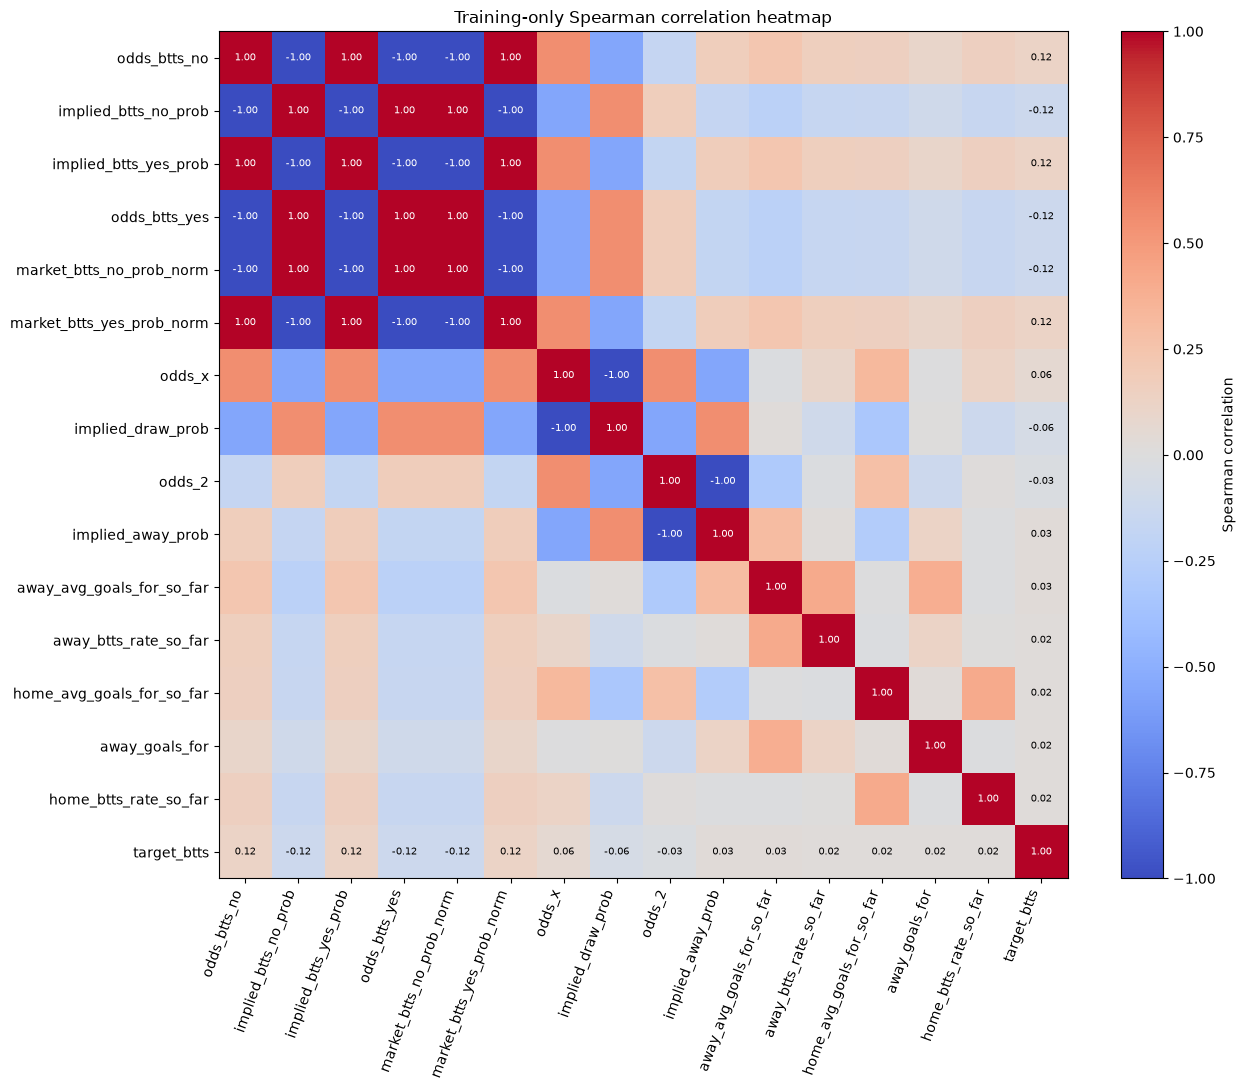

,feature_1,feature_2,correlation,abs_correlation
30,odds_x,implied_draw_prob,-1.000000,1.000000
34,odds_btts_yes,implied_btts_yes_prob,-1.000000,1.000000
28,odds_1,implied_home_prob,-1.000000,1.000000
48,market_btts_yes_prob_norm,market_btts_no_prob_norm,-1.000000,1.000000
39,odds_btts_no,implied_btts_no_prob,-1.000000,1.000000
32,odds_2,implied_away_prob,-1.000000,1.000000
37,odds_btts_yes,market_btts_no_prob_norm,0.999927,0.999927
44,implied_btts_yes_prob,market_btts_yes_prob_norm,0.999927,0.999927
45,implied_btts_yes_prob,market_btts_no_prob_norm,-0.999927,0.999927
36,odds_btts_yes,market_btts_yes_prob_norm,-0.999927,0.999927


,feature,missing_pct,unique_values,std
52,odds_x,1.378018,38,0.349624
57,implied_draw_prob,1.378018,38,0.022242
54,odds_btts_yes,1.378018,75,0.178254
59,implied_btts_yes_prob,1.378018,75,0.064517
55,odds_btts_no,1.378018,76,0.347139
60,implied_btts_no_prob,1.378018,76,0.064630
61,btts_market_margin,1.378018,93,0.002103
53,odds_2,1.378018,106,1.243773
58,implied_away_prob,1.378018,106,0.098597
62,market_btts_yes_prob_norm,1.378018,117,0.060775


In [13]:
corr_data = train_df[MODEL_FEATURES + [TARGET_COLUMN]].select_dtypes(include=[np.number])
feature_quality = pd.DataFrame({
    "feature": MODEL_FEATURES,
    "missing_pct": [100 * train_df[c].isna().mean() for c in MODEL_FEATURES],
    "unique_values": [train_df[c].nunique(dropna=True) for c in MODEL_FEATURES],
    "std": [train_df[c].std(skipna=True) for c in MODEL_FEATURES],
})
usable = feature_quality.loc[feature_quality["std"].fillna(0) > 0, "feature"].tolist()
spearman = corr_data[usable + [TARGET_COLUMN]].corr(method="spearman")
target_corr = (spearman[TARGET_COLUMN].drop(TARGET_COLUMN).rename("correlation_with_btts").to_frame()
               .assign(abs_correlation=lambda d: d["correlation_with_btts"].abs())
               .sort_values("abs_correlation", ascending=False))
display(target_corr.head(25))
heatmap_cols = target_corr.head(15).index.tolist() + [TARGET_COLUMN]
heatmap = spearman.loc[heatmap_cols, heatmap_cols]
fig, ax = plt.subplots(figsize=(13, 11))
image = ax.imshow(heatmap, vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
ax.set_xticks(range(len(heatmap_cols)), labels=heatmap_cols, rotation=70, ha="right")
ax.set_yticks(range(len(heatmap_cols)), labels=heatmap_cols)
ax.set_title("Training-only Spearman correlation heatmap")
for r in range(len(heatmap_cols)):
    for c in range(len(heatmap_cols)):
        v = heatmap.iloc[r, c]
        if r == len(heatmap_cols)-1 or c == len(heatmap_cols)-1 or abs(v) >= 0.70:
            ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v)>=0.55 else "black")
fig.colorbar(image, ax=ax, label="Spearman correlation")
fig.tight_layout(); plt.show()
pairs = [{"feature_1": a, "feature_2": b, "correlation": spearman.loc[a,b]}
         for i,a in enumerate(usable) for b in usable[i+1:] if abs(spearman.loc[a,b]) >= 0.90]
pair_report = pd.DataFrame(pairs)
if not pair_report.empty: pair_report = pair_report.assign(abs_correlation=pair_report["correlation"].abs()).sort_values("abs_correlation", ascending=False)
display(pair_report.head(30) if not pair_report.empty else pd.DataFrame({"message":["No feature pairs at |correlation| >= 0.90"]}))
display(feature_quality.sort_values(["missing_pct","unique_values"], ascending=[False,True]).head(25))

## 9. Train Model

This section trains several candidate models on the same features and validation split, then keeps the one with the highest validation accuracy.

In [14]:
candidate_models = {
    "LogisticRegression": LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE),
    "GradientBoostingClassifier": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "HistGradientBoostingClassifier": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    "RandomForestClassifier": RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=8,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
    "ExtraTreesClassifier": ExtraTreesClassifier(
        n_estimators=400,
        min_samples_leaf=8,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
    "SoftVotingEnsemble": VotingClassifier(
        estimators=[
            ("lr", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE)),
            ("gb", GradientBoostingClassifier(random_state=RANDOM_STATE)),
            ("hgb", HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
            ("rf", RandomForestClassifier(n_estimators=400, min_samples_leaf=8, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1)),
            ("et", ExtraTreesClassifier(n_estimators=400, min_samples_leaf=8, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1)),
        ],
        voting="soft",
    ),
}

model_results = []
trained_models = {}

for model_name, estimator in candidate_models.items():
    candidate = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("classifier", estimator),
        ]
    )
    candidate.fit(X_train, y_train)
    prob_yes = candidate.predict_proba(X_valid)[:, 1]
    pred = (prob_yes >= 0.5).astype(int)
    trained_models[model_name] = {"model": candidate, "prob": prob_yes, "pred": pred}
    model_results.append(
        {
            "model": model_name,
            "accuracy": accuracy_score(y_valid, pred),
            "roc_auc": roc_auc_score(y_valid, prob_yes) if y_valid.nunique() == 2 else np.nan,
            "brier_score": brier_score_loss(y_valid, prob_yes),
        }
    )

model_comparison = pd.DataFrame(model_results).sort_values(
    ["accuracy", "brier_score"],
    ascending=[False, True],
).reset_index(drop=True)
display(model_comparison)

best_model_name = model_comparison.loc[0, "model"]
model = trained_models[best_model_name]["model"]
valid_prob = trained_models[best_model_name]["prob"]
valid_pred = trained_models[best_model_name]["pred"]

print("Best model:", best_model_name)
print("Accuracy:", round(accuracy_score(y_valid, valid_pred), 3))
print("ROC AUC:", round(roc_auc_score(y_valid, valid_prob), 3) if y_valid.nunique() == 2 else "not available")
print("Brier score:", round(brier_score_loss(y_valid, valid_prob), 3))
print("Confusion matrix:")
print(confusion_matrix(y_valid, valid_pred))
print("\nClassification report:")
print(classification_report(y_valid, valid_pred, target_names=["BTTS No", "BTTS Yes"]))

,model,accuracy,roc_auc,brier_score
0,GradientBoostingClassifier,0.588044,0.572253,0.239923
1,HistGradientBoostingClassifier,0.586462,0.571306,0.239966
2,SoftVotingEnsemble,0.578636,0.572713,0.241430
3,RandomForestClassifier,0.560819,0.561861,0.245381
4,ExtraTreesClassifier,0.560153,0.564391,0.245413
5,LogisticRegression,0.559071,0.575544,0.245235


Best model: GradientBoostingClassifier
Accuracy: 0.588
ROC AUC: 0.572
Brier score: 0.24
Confusion matrix:
[[ 596 4443]
 [ 505 6467]]

Classification report:
              precision    recall  f1-score   support

     BTTS No       0.54      0.12      0.19      5039
    BTTS Yes       0.59      0.93      0.72      6972

    accuracy                           0.59     12011
   macro avg       0.57      0.52      0.46     12011
weighted avg       0.57      0.59      0.50     12011



## 9A. Explainable AI: Permutation Feature Importance

Permutation importance measures how much validation Brier score worsens when a feature is shuffled. Larger positive values mean more influence on unseen-match probabilities. Correlated features share credit, so read this beside the correlation heatmap.

,feature,importance_mean,importance_std,reliably_positive
0,market_btts_yes_prob_norm,0.000835,0.000287,True
1,implied_btts_no_prob,0.000647,0.000299,True
2,odds_btts_yes,0.000417,0.000177,True
3,home_losses,0.000376,0.000163,True
4,market_btts_no_prob_norm,0.000353,0.000226,True
5,implied_btts_yes_prob,0.000291,0.000189,True
6,btts_rate_diff,0.000181,0.000026,True
7,away_played,0.000170,0.000067,True
8,season_home_win_rate_so_far,0.000168,0.000161,True
9,conceded_rate_diff,0.000155,0.000076,True


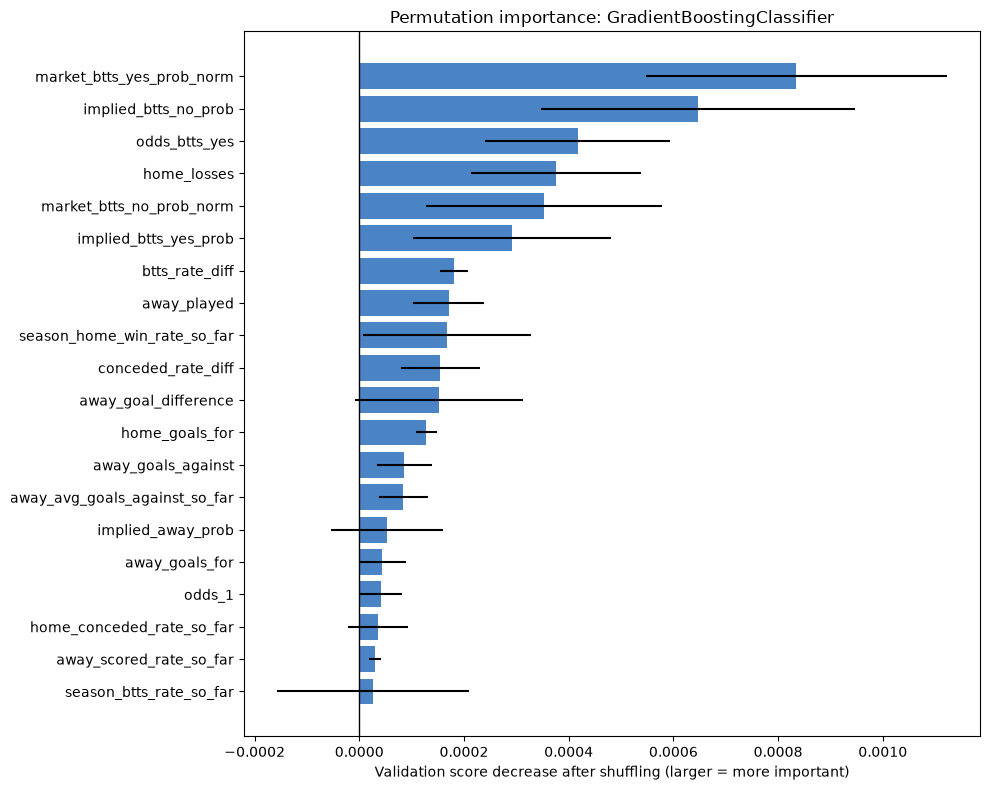

Strongly consider features whose importance is positive beyond the error bar and remains stable over later validation periods.


In [15]:
sample_n = min(1500, len(X_valid))
xai_x = X_valid.sample(sample_n, random_state=RANDOM_STATE)
xai_y = y_valid.loc[xai_x.index]
perm = permutation_importance(model, xai_x, xai_y, scoring="neg_brier_score", n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
importance_report = pd.DataFrame({"feature": MODEL_FEATURES, "importance_mean": perm.importances_mean, "importance_std": perm.importances_std})
importance_report = importance_report.sort_values("importance_mean", ascending=False).reset_index(drop=True)
importance_report["reliably_positive"] = importance_report["importance_mean"] > importance_report["importance_std"]
display(importance_report.head(25))
plot_importance = importance_report.head(20).sort_values("importance_mean")
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(plot_importance["feature"], plot_importance["importance_mean"], xerr=plot_importance["importance_std"], color="#2a6fbb", alpha=0.85)
ax.axvline(0, color="black", linewidth=1); ax.set_title(f"Permutation importance: {best_model_name}")
ax.set_xlabel("Validation score decrease after shuffling (larger = more important)"); fig.tight_layout(); plt.show()
print("Strongly consider features whose importance is positive beyond the error bar and remains stable over later validation periods.")

## 10. Pick / Skip Threshold Check

This matters more than raw accuracy. Low failure comes from skipping weak matches.

`confidence = max(prob_yes, prob_no)`

In [16]:
def evaluate_thresholds(y_true: pd.Series, prob_yes: np.ndarray) -> pd.DataFrame:
    rows = []
    for threshold in np.arange(0.50, 0.81, 0.05):
        pred = (prob_yes >= 0.5).astype(int)
        confidence = np.maximum(prob_yes, 1 - prob_yes)
        picked = confidence >= threshold
        if picked.sum() == 0:
            hit_rate = np.nan
        else:
            hit_rate = (pred[picked] == y_true.to_numpy()[picked]).mean()
        rows.append(
            {
                "threshold": round(float(threshold), 2),
                "picked_matches": int(picked.sum()),
                "coverage": round(float(picked.mean()), 3),
                "picked_hit_rate": np.nan if pd.isna(hit_rate) else round(float(hit_rate), 3),
            }
        )
    return pd.DataFrame(rows)


threshold_report = evaluate_thresholds(y_valid, valid_prob)
display(threshold_report)

,threshold,picked_matches,coverage,picked_hit_rate
0,0.50,12011,1.000,0.588
1,0.55,9039,0.753,0.605
2,0.60,5082,0.423,0.643
3,0.65,1800,0.150,0.664
4,0.70,221,0.018,0.701
5,0.75,6,0.000,0.167
6,0.80,0,0.000,NaN


## 10A. Goal-Focused Model Checks

Accuracy alone is not enough for betting. These checks compare simple and market baselines, inspect calibration, backtest flat-stake ROI where odds exist, show hit-rate uncertainty, test time stability, and audit the feature cutoff for leakage. Historical ROI is not a promise of future profit.

,method,rows,accuracy,roc_auc,brier_score
2,Market probability,11925,0.588428,0.577472,0.239347
0,Selected model,12011,0.588044,0.572253,0.239923
1,Train prevalence,12011,0.580468,0.500000,0.243529


,bin,matches,mean_probability,actual_btts_rate
0,"(-0.001, 0.1]",0,NaN,NaN
1,"(0.1, 0.2]",0,NaN,NaN
2,"(0.2, 0.3]",7,0.258636,0.571429
3,"(0.3, 0.4]",31,0.378452,0.483871
4,"(0.4, 0.5]",1063,0.465466,0.457197
5,"(0.5, 0.6]",5866,0.558596,0.548415
6,"(0.6, 0.7]",4830,0.637028,0.641408
7,"(0.7, 0.8]",214,0.712262,0.710280
8,"(0.8, 0.9]",0,NaN,NaN
9,"(0.9, 1.0]",0,NaN,NaN


Expected calibration error (lower is better): 0.008


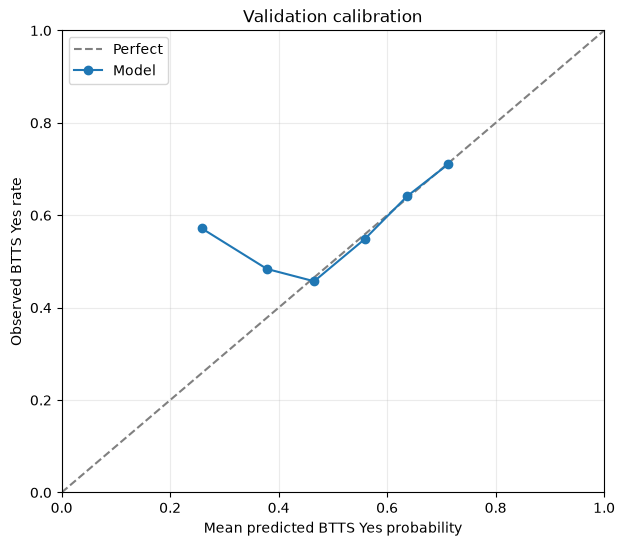

,threshold,bets,coverage,hit_rate,hit_rate_95pct_low,hit_rate_95pct_high,average_odds,profit_units,roi
0,0.50,11925,0.992840,0.587925,0.579063,0.596729,1.611368,-724.69,-0.060771
5,0.55,8953,0.745400,0.605495,0.595328,0.615572,1.552004,-596.96,-0.066677
10,0.60,5042,0.419782,0.644189,0.630868,0.657290,1.479804,-251.61,-0.049903
15,0.65,1800,0.149863,0.664444,0.642301,0.685888,1.409378,-119.02,-0.066122
17,0.67,1004,0.083590,0.665339,0.635569,0.693848,1.392470,-76.90,-0.076594
20,0.70,221,0.018400,0.701357,0.637996,0.757838,1.383756,-8.26,-0.037376
25,0.75,6,0.000500,0.166667,0.030053,0.563509,1.711667,-4.66,-0.776667


,time_block,matches,accuracy,roc_auc,brier_score
0,1,2403,0.584270,0.573880,0.241093
1,2,2402,0.610325,0.574091,0.237221
2,3,2402,0.590341,0.578132,0.238361
3,4,2402,0.569525,0.572749,0.242982
4,5,2402,0.585762,0.563353,0.239959


Feature-cutoff leakage violations: 0
Duplicate validation fixtures: 0
Trust a threshold only when calibration, sample size, time stability, and odds-based ROI agree.


In [17]:
audit = valid_df[TRACKING_COLUMNS + [TARGET_COLUMN]].copy()
audit["prob_yes"] = valid_prob; audit["prediction"] = valid_pred
audit["confidence"] = np.maximum(valid_prob, 1 - valid_prob)
baseline_report = pd.DataFrame([{"method":"Selected model","rows":len(y_valid),"accuracy":accuracy_score(y_valid,valid_pred),"roc_auc":roc_auc_score(y_valid,valid_prob),"brier_score":brier_score_loss(y_valid,valid_prob)},
    {"method":"Train prevalence","rows":len(y_valid),"accuracy":accuracy_score(y_valid,np.repeat(int(y_train.mean()>=0.5),len(y_valid))),"roc_auc":0.5,"brier_score":brier_score_loss(y_valid,np.repeat(y_train.mean(),len(y_valid)))}])
odds_ok = valid_df[["odds_btts_yes","odds_btts_no"]].notna().all(axis=1)
if odds_ok.any():
    raw_yes=1/valid_df.loc[odds_ok,"odds_btts_yes"]; raw_no=1/valid_df.loc[odds_ok,"odds_btts_no"]
    market_prob=raw_yes/(raw_yes+raw_no); market_y=y_valid.loc[odds_ok]
    baseline_report.loc[len(baseline_report)] = ["Market probability",int(odds_ok.sum()),accuracy_score(market_y,market_prob>=0.5),roc_auc_score(market_y,market_prob),brier_score_loss(market_y,market_prob)]
display(baseline_report.sort_values("brier_score"))
cal = pd.DataFrame({"prob_yes":valid_prob,"actual":y_valid.to_numpy()})
cal["bin"] = pd.cut(cal["prob_yes"], np.linspace(0,1,11), include_lowest=True)
calibration_report = cal.groupby("bin",observed=False).agg(matches=("actual","size"),mean_probability=("prob_yes","mean"),actual_btts_rate=("actual","mean")).reset_index()
display(calibration_report)
nonempty=calibration_report[calibration_report["matches"]>0]
ece=np.average((nonempty["mean_probability"]-nonempty["actual_btts_rate"]).abs(),weights=nonempty["matches"])
print("Expected calibration error (lower is better):",round(float(ece),4))
fig,ax=plt.subplots(figsize=(7,6)); ax.plot([0,1],[0,1],"--",color="gray",label="Perfect")
ax.plot(nonempty["mean_probability"],nonempty["actual_btts_rate"],marker="o",label="Model")
ax.set(xlabel="Mean predicted BTTS Yes probability",ylabel="Observed BTTS Yes rate",title="Validation calibration",xlim=(0,1),ylim=(0,1)); ax.legend(); ax.grid(alpha=.25); plt.show()
def wilson(wins,total,z=1.96):
    if total==0: return np.nan,np.nan
    p=wins/total; d=1+z*z/total; c=(p+z*z/(2*total))/d; m=z*np.sqrt(p*(1-p)/total+z*z/(4*total*total))/d; return c-m,c+m
roi_rows=[]
for threshold in sorted(set(np.round(np.arange(.50,.76,.01),2)).union({.65,.67})):
    picked=audit["confidence"].ge(threshold).to_numpy() & odds_ok.to_numpy(); rows=valid_df.loc[picked]
    actual=y_valid.loc[picked].to_numpy(); predicted=valid_pred[picked]
    chosen_odds=np.where(predicted==1,rows["odds_btts_yes"],rows["odds_btts_no"]); wins=predicted==actual
    profit=np.where(wins,chosen_odds-1,-1); low,high=wilson(int(wins.sum()),len(wins))
    roi_rows.append({"threshold":threshold,"bets":len(wins),"coverage":len(wins)/len(y_valid),"hit_rate":wins.mean() if len(wins) else np.nan,"hit_rate_95pct_low":low,"hit_rate_95pct_high":high,"average_odds":chosen_odds.mean() if len(wins) else np.nan,"profit_units":profit.sum() if len(wins) else 0,"roi":profit.mean() if len(wins) else np.nan})
roi_report=pd.DataFrame(roi_rows); display(roi_report[roi_report["threshold"].isin([.50,.55,.60,.65,.67,.70,.75])])
audit["time_block"]=pd.qcut(np.arange(len(audit)),q=min(5,len(audit)),labels=False,duplicates="drop")+1
stability=[]
for block,g in audit.groupby("time_block"):
    stability.append({"time_block":int(block),"matches":len(g),"accuracy":accuracy_score(g[TARGET_COLUMN],g["prediction"]),"roc_auc":roc_auc_score(g[TARGET_COLUMN],g["prob_yes"]),"brier_score":brier_score_loss(g[TARGET_COLUMN],g["prob_yes"])})
display(pd.DataFrame(stability))
cutoff_errors=(audit["feature_cutoff_matchday"]>audit["target_matchday"]-LIVE_GAP_MATCHDAYS).sum()
duplicates=audit.duplicated(["season_id","target_matchday","home_team","away_team"]).sum()
print("Feature-cutoff leakage violations:",int(cutoff_errors)); print("Duplicate validation fixtures:",int(duplicates))
print("Trust a threshold only when calibration, sample size, time stability, and odds-based ROI agree.")

## 11. Save Model

The notebook saves two important files:

- `models/btts_model.joblib`
- `models/btts_feature_columns.json`

Streamlit will load these later.

In [18]:
model_path = MODEL_DIR / "btts_model.joblib"
columns_path = MODEL_DIR / "btts_feature_columns.json"

dump(model, model_path)
columns_payload = {
    "target": TARGET_COLUMN,
    "feature_columns": MODEL_FEATURES,
    "excluded_all_missing_features": ALL_MISSING_FEATURES,
    "selected_model_name": best_model_name,
    "model_comparison": model_comparison.round(4).to_dict(orient="records"),
    "live_gap_matchdays": LIVE_GAP_MATCHDAYS,
    "pick_threshold": PICK_THRESHOLD,
    "notes": "For live MD 24 prediction while MD 23 is playing, build features using results up to MD 22 and MD 24 odds.",
}
columns_path.write_text(json.dumps(columns_payload, indent=2), encoding="utf-8")

print("Saved model:", model_path)
print("Saved feature columns:", columns_path)

Saved model: D:\Codex things\BP\models\btts_model.joblib
Saved feature columns: D:\Codex things\BP\models\btts_feature_columns.json


## 12. Live Prediction Example

This is the part Streamlit will later copy.

When MD 23 is live and you are betting MD 24:

```text
LIVE_SEASON_ID = current season
TARGET_MATCHDAY = 24
FEATURE_CUTOFF_MATCHDAY = 22
```

The saved model is not retrained here. We only build the latest feature rows and call `predict_proba`.

In [19]:
def latest_season_id(results_df: pd.DataFrame) -> str:
    numeric = pd.to_numeric(results_df["season_id"], errors="coerce")
    if numeric.notna().any():
        return str(int(numeric.max()))
    return str(results_df["season_id"].sort_values().iloc[-1])


def latest_fixture_odds(odds_df: pd.DataFrame, target_matchday: int | None = None) -> pd.DataFrame:
    if odds_df.empty:
        raise ValueError("No odds rows available. Capture upcoming odds first.")
    if target_matchday is None:
        target_matchday = int(odds_df["matchday"].max())
    fixtures = odds_df[odds_df["matchday"] == target_matchday].copy()
    if fixtures.empty:
        raise ValueError(f"No odds rows found for matchday {target_matchday}.")
    if "captured_at" in fixtures.columns:
        fixtures = fixtures.sort_values("captured_at")
    fixtures = fixtures.drop_duplicates(["matchday", "home_team", "away_team"], keep="last")
    return fixtures[["matchday", "home_team", "away_team"] + [c for c in ODDS_FEATURE_COLUMNS if c in fixtures.columns]].copy()


def build_live_prediction_table(
    results_df: pd.DataFrame,
    fixture_odds_df: pd.DataFrame,
    season_id: str,
    feature_cutoff_matchday: int,
) -> pd.DataFrame:
    bundle = make_stats_bundle(results_df, season_id, feature_cutoff_matchday)
    records = []
    for _, fixture in fixture_odds_df.iterrows():
        match = pd.Series(
            {
                "season_id": season_id,
                "matchday": int(fixture["matchday"]),
                "home_team": fixture["home_team"],
                "away_team": fixture["away_team"],
            }
        )
        record = build_base_feature_record(match, bundle, include_target=False)
        record["feature_cutoff_matchday"] = feature_cutoff_matchday
        for col in ODDS_FEATURE_COLUMNS:
            record[col] = fixture[col] if col in fixture.index else np.nan
        records.append(record)
    return pd.DataFrame(records)


# Edit these when you know the current situation.
LIVE_SEASON_ID = latest_season_id(results)
TARGET_MATCHDAY = None  # None means use the latest matchday available in final_odds_master.csv

fixture_odds = latest_fixture_odds(odds, TARGET_MATCHDAY)
TARGET_MATCHDAY = int(fixture_odds["matchday"].iloc[0])
FEATURE_CUTOFF_MATCHDAY = TARGET_MATCHDAY - LIVE_GAP_MATCHDAYS

live_df = build_live_prediction_table(results, fixture_odds, LIVE_SEASON_ID, FEATURE_CUTOFF_MATCHDAY)
display(live_df[["season_id", "target_matchday", "feature_cutoff_matchday", "home_team", "away_team", "odds_btts_yes", "odds_btts_no"]].head())
print("Live season:", LIVE_SEASON_ID)
print("Predicting matchday:", TARGET_MATCHDAY)
print("Using results up to matchday:", FEATURE_CUTOFF_MATCHDAY)

,season_id,target_matchday,feature_cutoff_matchday,home_team,away_team,odds_btts_yes,odds_btts_no
0,138971,34,32,CHE,EVE,1.53,2.45
1,138971,34,32,IPS,HUL,1.58,2.35
2,138971,34,32,BOU,COV,1.93,1.83
3,138971,34,32,LEE,CRY,1.56,2.35
4,138971,34,32,TOT,IPS,1.46,2.65


Live season: 138971
Predicting matchday: 34
Using results up to matchday: 32


In [20]:
saved_model = load(MODEL_DIR / "btts_model.joblib")
saved_columns = json.loads((MODEL_DIR / "btts_feature_columns.json").read_text(encoding="utf-8"))["feature_columns"]

for col in saved_columns:
    if col not in live_df.columns:
        live_df[col] = np.nan

live_prob_yes = saved_model.predict_proba(live_df[saved_columns])[:, 1]
predictions = live_df[["season_id", "target_matchday", "feature_cutoff_matchday", "home_team", "away_team", "odds_btts_yes", "odds_btts_no"]].copy()
predictions["btts_yes_probability"] = live_prob_yes
predictions["prediction"] = np.where(predictions["btts_yes_probability"] >= 0.5, "Yes", "No")
predictions["confidence"] = np.maximum(predictions["btts_yes_probability"], 1 - predictions["btts_yes_probability"])
predictions["decision"] = np.where(predictions["confidence"] >= PICK_THRESHOLD, "Pick", "Skip")

predictions = predictions.sort_values(["decision", "confidence"], ascending=[True, False]).reset_index(drop=True)
display(predictions)

prediction_path = OUTPUT_DIR / f"btts_predictions_md{TARGET_MATCHDAY}.csv"
predictions.to_csv(prediction_path, index=False)
print("Saved predictions:", prediction_path)

,season_id,target_matchday,feature_cutoff_matchday,home_team,away_team,odds_btts_yes,odds_btts_no,btts_yes_probability,prediction,confidence,decision
0,138971,34,32,BHA,NEW,1.46,2.65,0.669415,Yes,0.669415,Pick
1,138971,34,32,TOT,IPS,1.46,2.65,0.649310,Yes,0.649310,Skip
2,138971,34,32,LEE,MCI,1.44,2.70,0.645982,Yes,0.645982,Skip
3,138971,34,32,TOT,FUL,1.46,2.65,0.639485,Yes,0.639485,Skip
4,138971,34,32,NOT,TOT,1.45,2.70,0.633095,Yes,0.633095,Skip
5,138971,34,32,NEW,MCI,1.45,2.65,0.630842,Yes,0.630842,Skip
6,138971,34,32,AST,LIV,1.51,2.50,0.616977,Yes,0.616977,Skip
7,138971,34,32,CHE,HUL,1.58,2.35,0.608294,Yes,0.608294,Skip
8,138971,34,32,COV,BHA,1.60,2.30,0.603253,Yes,0.603253,Skip
9,138971,34,32,CHE,EVE,1.53,2.45,0.601600,Yes,0.601600,Skip


Saved predictions: D:\Codex things\BP\data\outputs\btts_predictions_md34.csv


## What Streamlit Will Consume Later

Streamlit will not train the model. It will only do this:

```text
1. Load models/btts_model.joblib
2. Load models/btts_feature_columns.json
3. Read latest results CSV and latest odds CSV
4. Build live features using target_matchday - 2
5. Show BTTS probability, prediction, confidence, Pick/Skip
```

That is how the notebook model is consumed.